In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

In [2]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANNEL = 3
EPOCHS = 50

In [3]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
"PlantVillage",
shuffle = True,
image_size = (IMAGE_SIZE, IMAGE_SIZE),
batch_size = BATCH_SIZE)

Found 2152 files belonging to 3 classes.


In [4]:
class_names = dataset.class_names

In [5]:
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [6]:
len(dataset) #nber of image under one batch means 2152/32

68

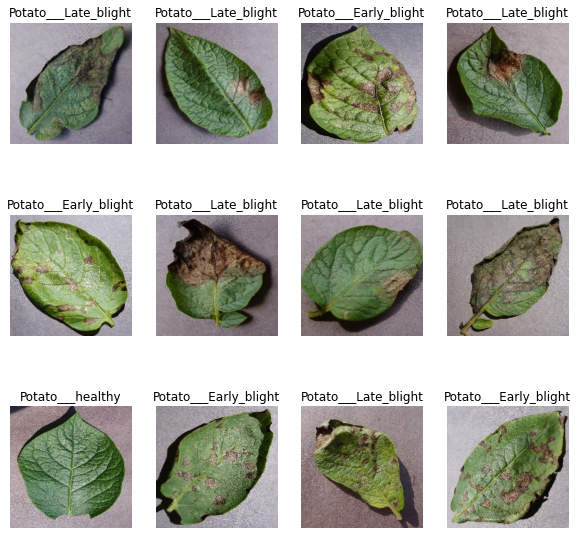

In [7]:
plt.figure(figsize=(10, 10))
for image_batch, label_batch in dataset.take(1):
    # print(image_batch.shape) # returned (32, 256, 256, 3) means we've 32 images bcs of batch size n each img has 256*256 with 3 as color channel
    # print(image_batch[2].numpy())
    # print(label_batch.numpy()) # label_batch has 4 value [0,1,2 respectively for 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
    # .numpy() will transform tensor into an array as our img are in tensor
    for i in range(12):
        ax = plt.subplot(3,4,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[label_batch[i]])
        plt.axis("off") # hide plot coordinate

In [ ]:
'''
80% ==> training
20% ==> 10% validation, 10% test
'''

'\n80% ==> training\n20% ==> 10% validation, 10% test\n'

In [8]:
train_size = 0.8 # means 80% of our dataset
training_sz = int(len(dataset)* train_size)

In [9]:
training_sz

54

In [11]:
train_ds = dataset.take(training_sz)

In [12]:
sz = len(train_ds)

In [13]:
test_ds = dataset.skip(sz)

In [14]:
len(test_ds)

14

In [15]:
val_size = 0.1 # means 10% here in test dataset

In [16]:
val_sz = int(len(dataset)*val_size)

In [17]:
val_sz

6

In [18]:
val_ds = test_ds.take(val_sz)
len(val_ds)

6

In [19]:
test_ds = test_ds.skip(val_sz)
len(test_ds)

8

In [20]:
def get_dataset_partitions_tf(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=1000):
    ds_size = len(ds)

    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12) # seed used for variabilities of sampling it can be any positive value

    train_size = int(train_split*ds_size)
    val_size = int(val_split*ds_size)

    train_ds = ds.take(train_size)

    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)

    return train_ds, val_ds, test_ds


In [21]:
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)

In [22]:
len(train_ds)

54

In [23]:
len(val_ds)

6

In [24]:
len(test_ds)

8

In [25]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE) # cache() used to not load over n over again dataset from memory it'll cache from active memory
# prefetch() load data from cpu when gpu is running used to speed up processing time as cpu won't be idle when gpu is running
# buffer_size=tf.data.AUTOTUNE will let computer doing these process automatically
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)


In [26]:
resize_and_rescale = tf.keras.Sequential([
    layers.experimental.preprocessing.Rescaling(IMAGE_SIZE, IMAGE_SIZE),#used to prevent an img to take another dim when prediction
    layers.experimental.preprocessing.Rescaling(1.0/255) #rescale input image into range [0-1] it's like every input img pixel value will be multiply by 1/255.it's simply used to turn img into grayscale img
])

In [27]:
data_augmentation = tf.keras.Sequential([
    layers.experimental.preprocessing.RandomFlip("horizontal_and_vertical"),#used to utilize data augmtation avantages. Here we'll flip img
    layers.experimental.preprocessing.RandomRotation(0.2) ##used to utilize data augmtation avantages. img will be rotated by 20%.
])

In [28]:
input_shape=(BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNEL)
n_classes = 3

In [29]:
model = models.Sequential([
    resize_and_rescale,
    data_augmentation,
    layers.Conv2D(32, (3,3), activation='relu', input_shape = input_shape), # we've 32 #t filters n kernel siz is (3,3)
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'), # 64 nber of neuron
    layers.Dense(n_classes, activation='softmax'),
])

model.build(input_shape=input_shape)

In [ ]:
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (32, 256, 256, 3)         0         
                                                                 
 sequential_1 (Sequential)   (32, 256, 256, 3)         0         
                                                                 
 conv2d (Conv2D)             (32, 254, 254, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2D  (32, 127, 127, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (32, 125, 125, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (32, 62, 62, 64)         0         
 2D)                                                  

In [30]:
## Above trainable parameters are the weight
model.compile(
optimizer= 'adam',
loss= tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
metrics= ['accuracy']
)


In [31]:
# saved model computation in history so that we can do some operation later with it such as plotting, so on...
history = model.fit(
train_ds,
epochs= EPOCHS,
batch_size = BATCH_SIZE,
verbose=1, # it allows us to print lot of output so that we can see clear what's going on
validation_data = val_ds
)

Epoch 1/50
54/54 [==============================] - 162s 3s/step - loss: 1.1022 - accuracy: 0.5949 - val_loss: 0.5142 - val_accuracy: 0.8229
Epoch 2/50
54/54 [==============================] - 152s 3s/step - loss: 0.4088 - accuracy: 0.8264 - val_loss: 0.3607 - val_accuracy: 0.8385
Epoch 3/50
54/54 [==============================] - 166s 3s/step - loss: 0.2925 - accuracy: 0.8762 - val_loss: 0.3266 - val_accuracy: 0.8802
Epoch 4/50
54/54 [==============================] - 159s 3s/step - loss: 0.2091 - accuracy: 0.9253 - val_loss: 0.2692 - val_accuracy: 0.8958
Epoch 5/50
54/54 [==============================] - 154s 3s/step - loss: 0.2721 - accuracy: 0.8900 - val_loss: 0.2725 - val_accuracy: 0.8906
Epoch 6/50
54/54 [==============================] - 152s 3s/step - loss: 0.1700 - accuracy: 0.9340 - val_loss: 0.1455 - val_accuracy: 0.9479
Epoch 7/50
54/54 [==============================] - 154s 3s/step - loss: 0.1715 - accuracy: 0.9259 - val_loss: 0.1780 - val_accuracy: 0.9323
Epoch 8/50
54

In [32]:
scores = model.evaluate(test_ds)

8/8 [==============================] - 12s 815ms/step - loss: 0.0407 - accuracy: 0.9766


In [33]:
scores

[0.04067103937268257, 0.9765625]

In [34]:
history

In [35]:
history.params # #t parameter under history var

{'verbose': 1, 'epochs': 50, 'steps': 54}

In [36]:
history.history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [37]:
# history.history['accuracy']

In [38]:
# len(history.history['accuracy'])

In [39]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']


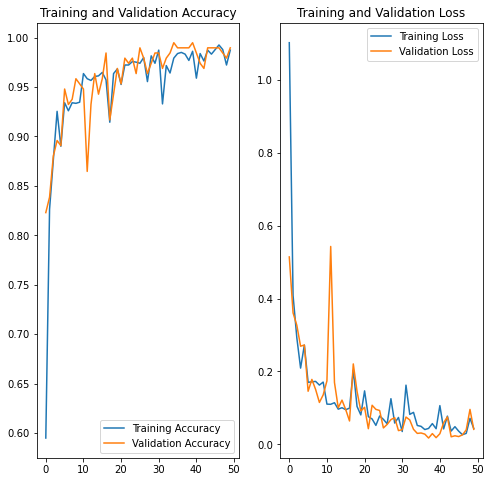

In [40]:
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label='Training Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

first image to predict
actual label: Potato___Early_blight
Potato___Early_blight


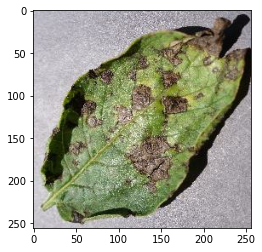

In [41]:
import numpy as np
for images_batch, labels_batch in test_ds.take(1):

    # print(images_batch[0].numpy())
    first_image = images_batch[0].numpy().astype('uint8')
    first_label = labels_batch[0]
    # plt.imshow(images_batch[0].numpy().astype('uint8'))

    print('first image to predict')
    plt.imshow(first_image)
    print("actual label:", class_names[first_label])

    batch_prediction = model.predict(images_batch)
    # print(batch_prediction[0]) # will output [1.000000e+00 2.365353e-08 3.114122e-13] is due to softmax funct as we've 3 classes max prediction value will win
    # print(np.argmax(batch_prediction[0])) # return maximum one in the list
    print(class_names[np.argmax(batch_prediction[0])])

In [42]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(img) # images[i].numpy() I've to cross check it
    img_array = tf.expand_dims(img_array, 0) # used to add one more dimension here it's to Create a batch means gives place for batch

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

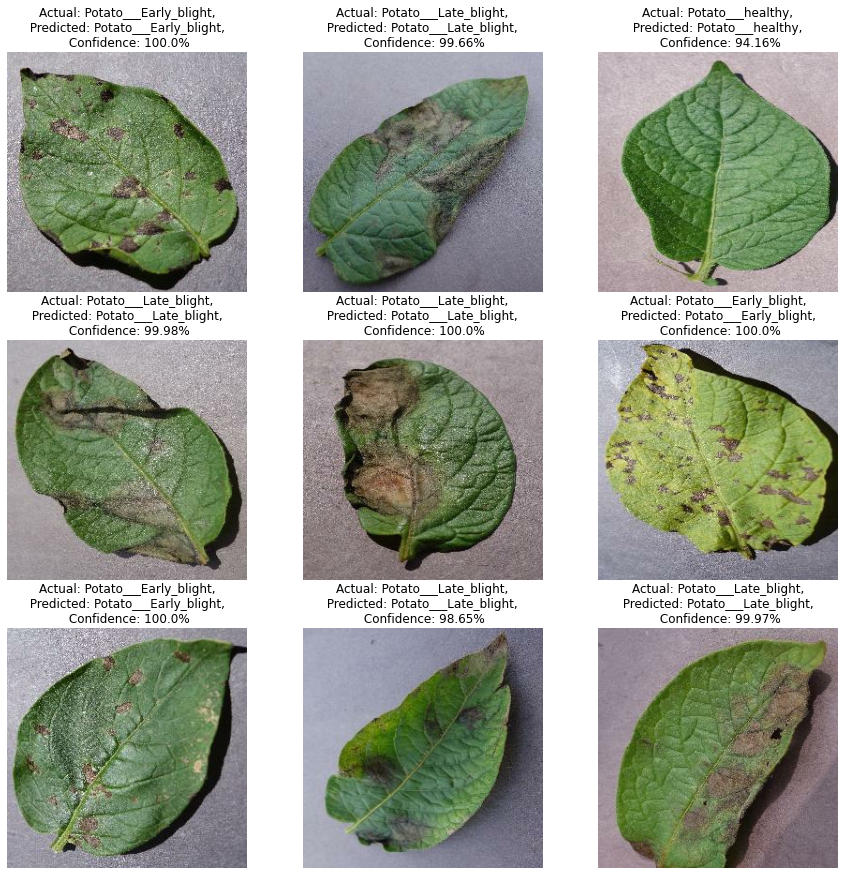

In [43]:
plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))

        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]]

        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}, \n Confidence: {confidence}%")

        plt.axis("off")

In [44]:
import os
# below one getting next model version
# go to paste dir n return it content as list + add 0 to list then converted elt into int, then pick the maximum one elt of the list.
model_version = max(int(i) for i in os.listdir("../saved_models") + [0]) + 1 # used to save our model in #t version

'''
ls = []
for i in os.listdir("../saved_models")+ [0]:
    if type(i) == str:
        s = i.split('.')[0]
        ls.append(int(s))
    else:
        ls.append(i)

model_version = max(ls) + 1
newpath = f'../saved_models/{model_version}'
if not os.path.exists(newpath):
    os.makedirs(newpath)
model.save(f"../saved_models/{model_version}/{model_version}.h5")  #we've save_format='keras', 'tf', 'pb'
'''
model.save(f"../saved_models/{model_version}")

INFO:tensorflow:Assets written to: ../saved_models/1\assets


In [ ]:
# model = tf.keras.models.load_model(f"../saved_models/{model_version}/{model_version}.h5")
# tf.saved_model.save(model, f'../md')